# 🤖 Notebook 2: Naive Bayes Baseline
**Project**: Sentiment Analysis on YouTube Comments  
**Model**: Multinomial Naive Bayes Baseline  
**Feature Engineering**: TF-IDF Vectorization (Unigrams & Bigrams, `max_features=5000`)  
**Objective**: Build a baseline sentiment classifier, evaluate standard performance metrics, visualize confusion matrix, and perform qualitative error analysis.


In [1]:
# Standard Imports
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Set seed for reproducibility
RANDOM_STATE = 42
print("Imports completed successfully!")


Imports completed successfully!


---
## 1. Data Loading & Stratified Train/Test Split
We load the pre-cleaned YouTube comments dataset, encode labels to integers, and perform an 80/20 stratified split.


In [2]:
# File Path Setup
KAGGLE_PATH = "/kaggle/input/datasets/amaanpoonawala/youtube-comments-sentiment-dataset/youtube_comments_cleaned.csv"
LOCAL_PATH = "youtube_comments_cleaned.csv"

data_path = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
df = pd.read_csv(data_path).dropna(subset=['CommentText', 'Sentiment']).reset_index(drop=True)
df['CommentText'] = df['CommentText'].astype(str)

# Map target sentiment classes
label_mapping = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
reverse_mapping = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
df['label'] = df['Sentiment'].map(label_mapping)

# Stratified Split (80% Train, 20% Test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df['CommentText'],
    df['label'],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df['label']
)

print(f"Training set size: {len(X_train_raw):,}")
print(f"Testing set size: {len(X_test_raw):,}")


Training set size: 590,533
Testing set size: 147,634


---
## 2. Feature Engineering: TF-IDF Vectorization
Transforming text data into TF-IDF feature matrices using unigrams and bigrams with `max_features=5000`.


In [3]:
# Initialize TfidfVectorizer
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000,
    stop_words='english'
)

# Fit on training data, transform both train and test
X_train_tfidf = vectorizer.fit_transform(X_train_raw)
X_test_tfidf = vectorizer.transform(X_test_raw)

print(f"TF-IDF Train Matrix Shape: {X_train_tfidf.shape}")
print(f"TF-IDF Test Matrix Shape: {X_test_tfidf.shape}")


TF-IDF Train Matrix Shape: (590533, 5000)
TF-IDF Test Matrix Shape: (147634, 5000)


---
## 3. Model Training: Multinomial Naive Bayes
Fitting the `MultinomialNB` classifier on the TF-IDF feature representations.


In [4]:
# Instantiate and Train Multinomial Naive Bayes
nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes training complete!")


Multinomial Naive Bayes training complete!


---
## 4. Evaluation & Confusion Matrix Heatmap
Evaluating predictions on the holdout test set using Accuracy, Classification Report, and Confusion Matrix.


=== Baseline Naive Bayes Test Accuracy: 60.09% ===

Classification Report:
              precision    recall  f1-score   support

    Negative       0.54      0.69      0.61     49488
     Neutral       0.57      0.49      0.53     49059
    Positive       0.72      0.62      0.66     49087

    accuracy                           0.60    147634
   macro avg       0.61      0.60      0.60    147634
weighted avg       0.61      0.60      0.60    147634



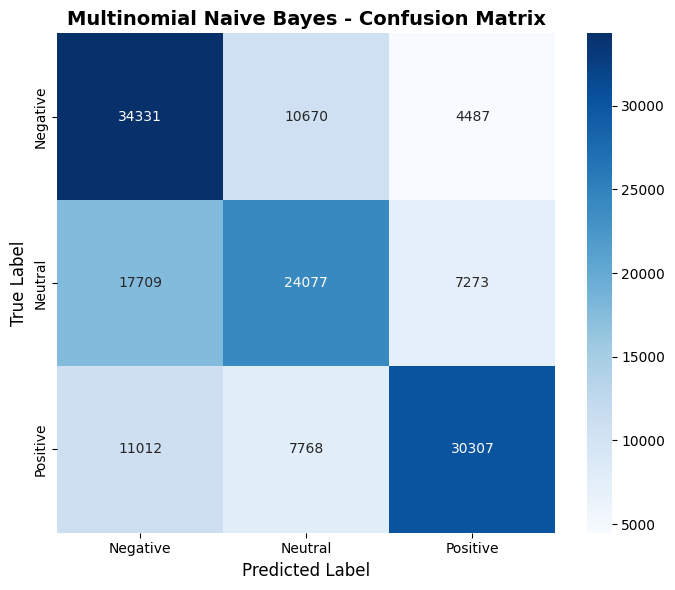

In [5]:
# Predictions
y_pred = nb_model.predict(X_test_tfidf)

# Metrics
acc = accuracy_score(y_test, y_pred)
print(f"=== Baseline Naive Bayes Test Accuracy: {acc * 100:.2f}% ===\n")

class_names = ['Negative', 'Neutral', 'Positive']
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Multinomial Naive Bayes - Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()


---
## 5. Qualitative Error Analysis
Examining 5 misclassified examples to observe where the bag-of-words / TF-IDF baseline fails (e.g., sarcasm, negation, neutral nuances).


In [10]:
test_results = pd.DataFrame({
    'CommentText': X_test_raw.values,
    'TrueLabel': [reverse_mapping[val] for val in y_test.values],
    'PredLabel': [reverse_mapping[val] for val in y_pred]
})

misclassified = test_results[test_results['TrueLabel'] != test_results['PredLabel']]

print(f"Total Misclassified Examples in Test Set: {len(misclassified):,} / {len(test_results):,}\n")
print("=== 5 Representative Misclassified Examples ===")

for idx, row in misclassified.head(5).reset_index(drop=True).iterrows():
    print(f"Example #{idx + 1}:")

    print(f"  Comment  : {row['CommentText']}")
    print(f"  True     : {row['TrueLabel']}")
    print(f"  Predicted: {row['PredLabel']}")
    print("-" * 70)

Total Misclassified Examples in Test Set: 58,919 / 147,634

=== 5 Representative Misclassified Examples ===
Example #1:
  Comment  : He's almost 80 years old.. Nothing early about it
  True     : Negative
  Predicted: Neutral
----------------------------------------------------------------------
Example #2:
  Comment  : I mean, it is crazy for them to make something that literally just looks like the SwitchXL or something. This IS Nintendo. Look at their lineup of consoles. Drastic changes from each console to the next. UNLESS, you talk about the handhelds. and if this Switch2 DOES look like this, then it would fall in line with the way Nintendo treats their handhelds, as opposed to the way they treat their consoles. Though I do hope it isn't called "Switch 2". My friend came up with a dumb ass name that's better than that, "The Switcheroo".
  True     : Neutral
  Predicted: Negative
----------------------------------------------------------------------
Example #3:
  Comment  : Your vi